# Supplementary Fig S3 · Gene-set search

The parts of the old Fig 4 (`_backup_2026-11-01/F4_gene_set.ipynb`) and of the draft accuracy figure
(`_backup_2026-11-01/draft_4fig/F3_accuracy.ipynb`, B and C) that are not in the main Fig 2 (search time and RDE / NNR
per section are main Fig 2B, C).

* **A** the typical breast query (|S| = 16): the exact d_B^S of every index tile (grey) and of the tiles Spindle
  returned; dashed, the distance of the c-th nearest index tile at c = 5 % of N.
* **B** RDE against |S|: Spindle, padding + Spindle-naive, imputation + Spindle-naive.
* **C** NNR against |S|, the same methods. B, C: per seed the median over the eight sections, mean ± s.d. over seeds.
* **D** time to compute the logarithms of a gene-set query: the block logarithms of Spindle-naive and the piece
  logarithms of Spindle (median per seed, mean ± s.d. over seeds).
* **E** stored MB per section: whole covariances, Spindle-naive, Spindle, padding, imputation.

**Run first:** `R3_gene_set` (`results/gene_set/`) and `R4_timing` (`results/timing/gene_set.csv`).
Writes `figures/figS3_gene_set/`.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

import gene_set_accuracy as gsa
import retrieval as rt
import style as ps

FIG = "figS3_gene_set"
RES = ROOT / "results" / "gene_set"
KEYS = ps.DATASET_ORDER
SPINDLE, NAIVE, WHOLE = ps.TIER_COLORS["spindle_partial"], ps.TIER_COLORS["naive"], ps.TIER_COLORS["whole"]
BASE = {"padding": "#44AA99", "imputation": "#882255"}
METHOD_LABEL = {"spindle_partial": "Spindle (gene sets)", "padding": "Padding + Spindle-naive",
                "imputation": "Imputation + Spindle-naive"}
MARK = {"spindle_partial": "^", "padding": "s", "imputation": "o"}
COLOR = {"spindle_partial": SPINDLE, **BASE}
H1, H2 = 52.0, 60.0
TOP, BOTTOM = 5.5, 10.0
LEG1 = 6.0

band = np.load(RES / "band" / "breast_cancer.npz")
nx_size = pd.read_csv(RES / "nx_size.csv")
storage = pd.read_csv(RES / "storage.csv").set_index("key")
_, _, timing = gsa.timing_tables(pd.read_csv(ROOT / "results" / "timing" / "gene_set.csv"))
timing = timing.set_index("key")
print(sorted(set(nx_size.tag) | set(storage.tag)))
timing[["qlog_naive_partial_ms", "qlog_spindle_partial_ms"]].round(2)


def rows_axis(ax, labels):
    ax.set_ylim(len(KEYS) - 0.5, -0.5)
    ax.set_yticks(range(len(KEYS)))
    ax.set_yticklabels([ps.DATASET_LABELS[k] for k in KEYS] if labels else [])
    ax.tick_params(axis="y", length=0)


def legend(fig, handles, ncol):
    fig.legend(handles=handles, ncol=ncol, loc="upper center", bbox_to_anchor=(0.5, 1.0), frameon=False)

['method-v2']


## A · The typical breast query, |S| = 16

breast typical gene-set query: N = 1840, returned 309, c = 92, d_c = 0.298
figures/figS3_gene_set/panels/A.pdf/.png: 62 x 52 mm, 0.0 / 0.3 MB


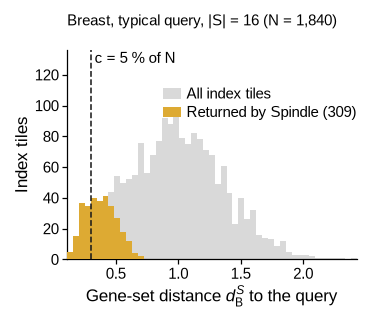

In [2]:
def panel_a(fig):
    d, found = band["d"], band["found"]
    c = rt.c5(len(d))
    d_c = np.sort(d)[c - 1]
    print(f"breast typical gene-set query: N = {len(d)}, returned {len(found)}, c = {c}, d_c = {d_c:.3f}")
    ax = ps.axes(fig, left=11.0, right=2.0, bottom=BOTTOM, top=TOP + 1.0)
    bins = np.linspace(d.min(), np.quantile(d, 0.995), 50)
    n_all, _, _ = ax.hist(d, bins=bins, color=ps.LIGHT, lw=0, zorder=2, label="All index tiles")
    ax.hist(d[found], bins=bins, color=SPINDLE, lw=0, zorder=3, label=f"Returned by Spindle ({len(found)})")
    ax.axvline(d_c, ls="--", lw=0.75, color=ps.INK, zorder=4)
    ax.text(d_c, 0.99, " c = 5 % of N", transform=ax.get_xaxis_transform(), ha="left", va="top", fontsize=ps.TICK_PT)
    ax.set_ylim(0, 1.45 * n_all.max())
    ax.set_xlabel(r"Gene-set distance $d^{S}_{\mathcal{B}}$ to the query")
    ax.set_ylabel("Index tiles")
    ax.set_xlim(bins[0], bins[-1])
    ax.legend(loc="upper right", bbox_to_anchor=(1.0, 0.82))
    W, H = ps.size_mm(fig)
    fig.text(11.0 / W, 1 - 0.5 / H, f"Breast, typical query, |S| = 16 (N = {len(d):,})", va="top",
             fontsize=ps.TICK_PT)


fig = ps.panel(62, H1); panel_a(fig); ps.save_panel(fig, FIG, "A")

## B, C · RDE and NNR against |S|

figures/figS3_gene_set/panels/B.pdf/.png: 59 x 52 mm, 0.0 / 0.2 MB
figures/figS3_gene_set/panels/C.pdf/.png: 59 x 52 mm, 0.0 / 0.2 MB


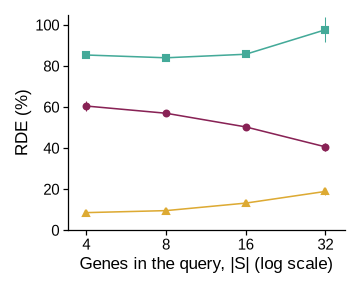

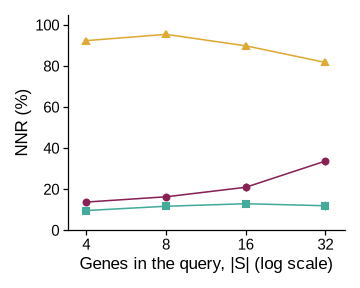

In [3]:
SIZE_HANDLES = [Line2D([], [], marker=MARK[m], ms=2.8, color=COLOR[m], label=METHOD_LABEL[m])
                for m in ("spindle_partial", "padding", "imputation")]


def by_size(fig, col, ylabel):
    ax = ps.axes(fig, left=10.0, right=2.0, bottom=BOTTOM, top=TOP)
    t = nx_size[nx_size["size"] > 0]
    for m in ("padding", "imputation", "spindle_partial"):
        s = t[t.method == m].sort_values("size")
        ax.errorbar(s["size"], 100 * s[col], yerr=100 * s[f"{col}_sd"], fmt=f"-{MARK[m]}", ms=2.8, color=COLOR[m],
                    elinewidth=0.5, zorder=3 if m == "spindle_partial" else 2)
    ax.set_xscale("log", base=2)
    ax.set_xticks([4, 8, 16, 32], ["4", "8", "16", "32"])
    ax.minorticks_off()
    ax.set_xlim(3.4, 38)
    ax.set_ylim(0, 105)
    ax.set_xlabel("Genes in the query, |S| (log scale)")
    ax.set_ylabel(ylabel)


def panel_b(fig):
    by_size(fig, "NX5", "RDE (%)")


def panel_c(fig):
    by_size(fig, "overlap5", "NNR (%)")


fig = ps.panel(59, H1); panel_b(fig); ps.save_panel(fig, FIG, "B")
fig = ps.panel(59, H1); panel_c(fig); ps.save_panel(fig, FIG, "C")

## D · Time to compute the logarithms of the query

figures/figS3_gene_set/panels/D.pdf/.png: 66 x 60 mm, 0.0 / 0.2 MB


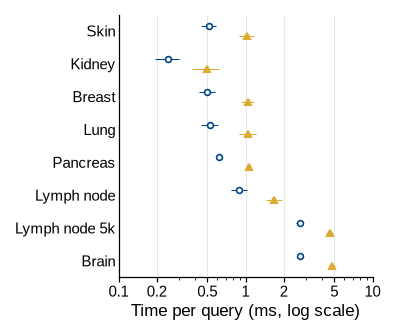

In [4]:
QLOG_HANDLES = [Line2D([], [], ls="", marker="o", ms=2.8, mfc="white", mec=NAIVE, mew=0.8,
                       label="Block logarithms (Spindle-naive)"),
                Line2D([], [], ls="", marker="^", ms=3.0, color=SPINDLE, label="Piece logarithms (Spindle)")]


def panel_d(fig):
    ax = ps.axes(fig, left=20.0, right=3.0, bottom=BOTTOM, top=TOP)
    for i, k in enumerate(KEYS):
        r = timing.loc[k]
        ax.errorbar(r.qlog_naive_partial_ms, i - 0.15, xerr=r.qlog_naive_partial_ms_sd, fmt="o", ms=2.8, mfc="white",
                    mec=NAIVE, mew=0.8, ecolor=NAIVE, elinewidth=0.5, zorder=3)
        ax.errorbar(r.qlog_spindle_partial_ms, i + 0.15, xerr=r.qlog_spindle_partial_ms_sd, fmt="^", ms=3.0,
                    color=SPINDLE, elinewidth=0.5, zorder=3)
    ax.set_xscale("log")
    ps.plain_log(ax, "x", subs=(1.0, 2.0, 5.0))
    ps.log_grid(ax, "x")
    ax.set_xlim(0.1, 10)
    rows_axis(ax, True)
    ax.set_xlabel("Time per query (ms, log scale)")


fig = ps.panel(66, H2); panel_d(fig); ps.save_panel(fig, FIG, "D")

## E · Storage

figures/figS3_gene_set/panels/E.pdf/.png: 114 x 60 mm, 0.0 / 0.3 MB


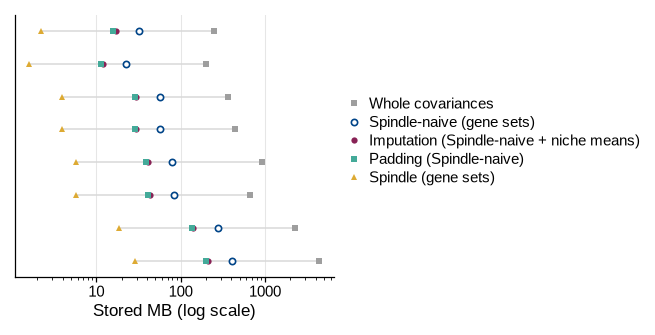

In [5]:
STORE = [("whole", WHOLE, "s"), ("naive_partial", NAIVE, "o"), ("imputation", BASE["imputation"], "o"),
         ("padding", BASE["padding"], "s"), ("spindle_partial", SPINDLE, "^")]
STORE_LABEL = {"whole": "Whole covariances", "naive_partial": "Spindle-naive (gene sets)",
               "imputation": "Imputation (Spindle-naive + niche means)", "padding": "Padding (Spindle-naive)",
               "spindle_partial": "Spindle (gene sets)"}
STORE_HANDLES = [Line2D([], [], ls="", marker=mk, ms=3.0, color=c, mfc="white" if col == "naive_partial" else c, mec=c,
                        mew=0.8 if col == "naive_partial" else 0, label=STORE_LABEL[col]) for col, c, mk in STORE]


def panel_e(fig):
    W, _ = ps.size_mm(fig)
    ax = ps.axes(fig, left=2.0, right=W - 56.0, bottom=BOTTOM, top=TOP)
    for i, k in enumerate(KEYS):
        r = storage.loc[k]
        ax.plot([r.spindle_partial, r.whole], [i, i], color=ps.LIGHT, lw=0.75, zorder=1)
        for col, c, mk in STORE:
            open_ = col == "naive_partial"
            ax.plot(r[col], i, mk, ms=3.0 if mk != "^" else 3.3, color=c, mfc="white" if open_ else c, mec=c,
                    mew=0.8 if open_ else 0, zorder=3 if col == "spindle_partial" else 2)
    ax.set_xscale("log")
    ps.plain_log(ax, "x", subs=(1.0,))
    ps.log_grid(ax, "x")
    rows_axis(ax, False)
    ax.set_xlabel("Stored MB (log scale)")
    fig.legend(handles=STORE_HANDLES, ncol=1, loc="center left", bbox_to_anchor=(58.0 / W, 0.55))


fig = ps.panel(114, H2); panel_e(fig); ps.save_panel(fig, FIG, "E")

## Full figure

breast typical gene-set query: N = 1840, returned 309, c = 92, d_c = 0.298
figures/figS3_gene_set/figS3_gene_set.pdf/.png: 180 x 128 mm, 0.0 / 1.3 MB


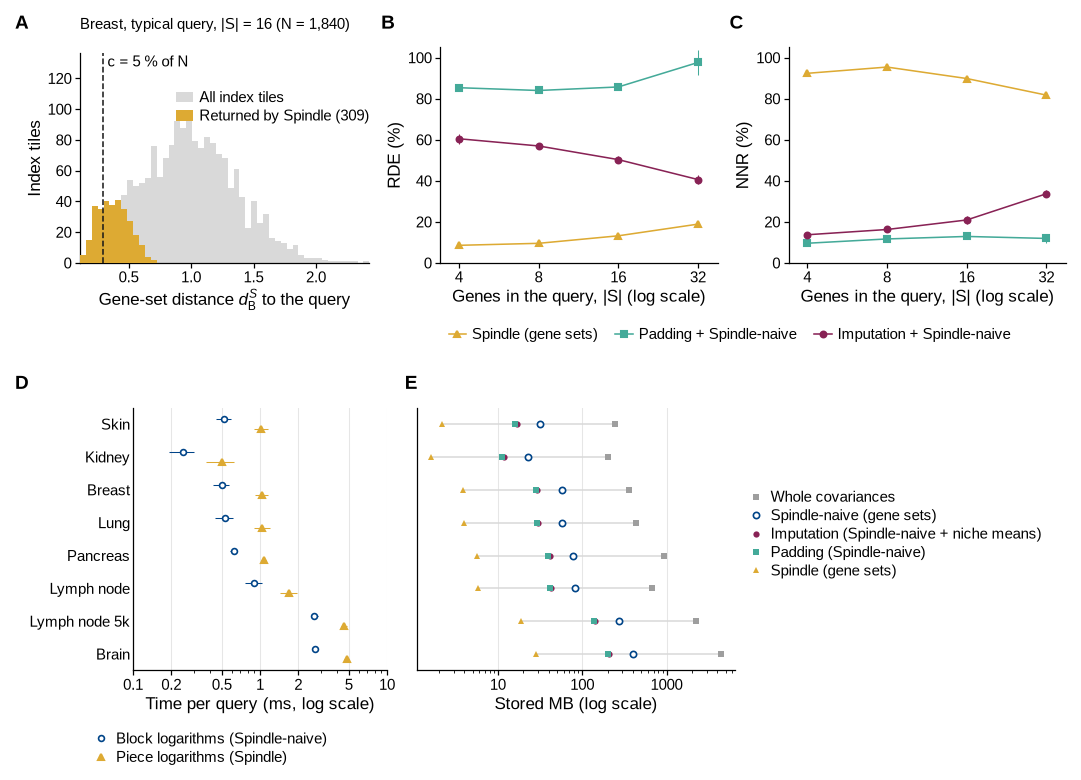

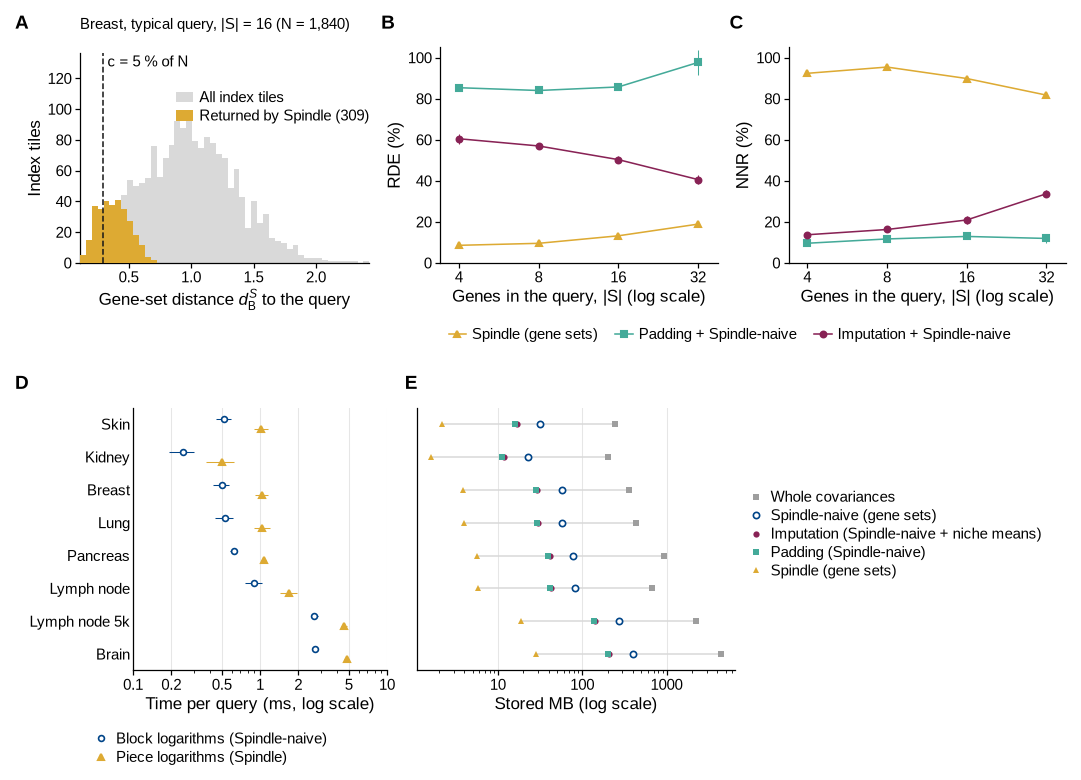

In [6]:
Y2 = H1 + LEG1 + 3.0
page = ps.page(180, Y2 + H2 + LEG1 + 1.0)
panel_a(ps.place(page, "A", 0, 0, 62, H1))
panel_b(ps.place(page, "B", 62, 0, 59, H1))
panel_c(ps.place(page, "C", 121, 0, 59, H1))
legend(ps.place(page, None, 62, H1 + 1.0, 118, LEG1), SIZE_HANDLES, 3)
panel_d(ps.place(page, "D", 0, Y2, 66, H2))
panel_e(ps.place(page, "E", 66, Y2, 114, H2))
legend(ps.place(page, None, 0, Y2 + H2 + 0.5, 66, LEG1), QLOG_HANDLES, 1)
ps.save_figure(page, FIG)
page